## Setup

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
from environment import AssetVecEnv, AssetEnvState, AssetEpisodeLog, log_to_dataframe
from preprocessing import preprocess, INDICATORS

## Environment

In [ ]:
from preprocessing import preprocess, INDICATORS

df     = preprocess()
config = {
    "price_array": df["close"].values.astype(np.float32),
    "tech_array":  df[INDICATORS].values.astype(np.float32),
    "date":        pd.to_datetime(df["date"]),
}

env = AssetVecEnv(config, n_envs=1, initial_cash=10_000.0,
                  commission_rate=1e-3, max_leverage=1.0, allow_shorts=True)

print(f"T={env.T}  F={env.tech_dim}")
print(f"obs_space: {env.observation_space}")
print(f"act_space: {env.action_space}\n")

obs = env.reset()
print(f"reset → obs shape {obs.shape}  obs[0, :4]={obs[0, :4]}\n")

actions_seq = [0, 1, 1, 1, 2, 2, 0, 1, 2, 0]
for step, act in enumerate(actions_seq):
    env.step_async(np.array([act]))
    obs, rew, done, info = env.step_wait()
    s      = env.states[0]
    suffix = f"  episode={info[0]['episode']}" if done[0] else ""
    print(f"step {step:2d}  act={act}  pos={s.position:+d}  "
          f"total_asset={s.total_asset:10.4f}  reward={rew[0]:+.6f}  done={done[0]}{suffix}")


Data shape: (65989, 7)
Date range: 2017-12-31 23:00:00 -> 2025-07-17 13:00:00
Processed shape: (65989, 93)
Indicators (86): ['volume_adi', 'volume_obv', 'volume_cmf', 'volume_fi', 'volume_em', 'volume_sma_em', 'volume_vpt', 'volume_vwap', 'volume_mfi', 'volume_nvi', 'volatility_bbm', 'volatility_bbh', 'volatility_bbl', 'volatility_bbw', 'volatility_bbp', 'volatility_bbhi', 'volatility_bbli', 'volatility_kcc', 'volatility_kch', 'volatility_kcl', 'volatility_kcw', 'volatility_kcp', 'volatility_kchi', 'volatility_kcli', 'volatility_dcl', 'volatility_dch', 'volatility_dcm', 'volatility_dcw', 'volatility_dcp', 'volatility_atr', 'volatility_ui', 'trend_macd', 'trend_macd_signal', 'trend_macd_diff', 'trend_sma_fast', 'trend_sma_slow', 'trend_ema_fast', 'trend_ema_slow', 'trend_vortex_ind_pos', 'trend_vortex_ind_neg', 'trend_vortex_ind_diff', 'trend_trix', 'trend_mass_index', 'trend_dpo', 'trend_kst', 'trend_kst_sig', 'trend_kst_diff', 'trend_ichimoku_conv', 'trend_ichimoku_base', 'trend_ichim

## DQN

In [7]:
# ── data splits ──────────────────────────────────────────────────────────────
TRAIN_MONTHS, VAL_MONTHS, TEST_MONTHS = 18, 6, 3

dates = pd.to_datetime(df["date"])
t0        = dates.iloc[0]
train_end = t0        + pd.DateOffset(months=TRAIN_MONTHS)
val_end   = train_end + pd.DateOffset(months=VAL_MONTHS)
test_end  = val_end   + pd.DateOffset(months=TEST_MONTHS)

mask_train = dates <  train_end
mask_val   = (dates >= train_end) & (dates < val_end)
mask_test  = (dates >= val_end)   & (dates < test_end)

def make_config(sub_df):
    return {
        "price_array": sub_df["close"].values.astype(np.float32),
        "tech_array":  sub_df[INDICATORS].values.astype(np.float32),
        "date":        pd.to_datetime(sub_df["date"]),
    }

ENV_KWARGS = dict(initial_cash=10_000.0, commission_rate=1e-3,
                  max_leverage=1.0, allow_shorts=True)

train_env = AssetVecEnv(make_config(df[mask_train].reset_index(drop=True)), n_envs=1, **ENV_KWARGS)
val_env   = AssetVecEnv(make_config(df[mask_val].reset_index(drop=True)),   n_envs=1, **ENV_KWARGS)
test_env  = AssetVecEnv(make_config(df[mask_test].reset_index(drop=True)),  n_envs=1, **ENV_KWARGS)
env = val_env   # downstream cells (activity, rollout) evaluate on val

for name, mask in [("train", mask_train), ("val", mask_val), ("test", mask_test)]:
    d = dates[mask]
    print(f"{name:5s}  bars={mask.sum():6d}  {d.iloc[0].date()} → {d.iloc[-1].date()}")


train  bars= 13026  2017-12-31 → 2019-06-30
val    bars=  4380  2019-06-30 → 2019-12-30
test   bars=  2177  2019-12-30 → 2020-03-30


In [1]:
from stable_baselines3 import DQN
help(DQN)

Help on class DQN in module stable_baselines3.dqn.dqn:

class DQN(stable_baselines3.common.off_policy_algorithm.OffPolicyAlgorithm)
 |  DQN(
 |      policy: str | type[stable_baselines3.dqn.policies.DQNPolicy],
 |      env: Union[gymnasium.core.Env, ForwardRef('VecEnv'), str],
 |      learning_rate: float | collections.abc.Callable[[float], float] = 0.0001,
 |      buffer_size: int = 1000000,
 |      learning_starts: int = 100,
 |      batch_size: int = 32,
 |      tau: float = 1.0,
 |      gamma: float = 0.99,
 |      train_freq: int | tuple[int, str] = 4,
 |      gradient_steps: int = 1,
 |      replay_buffer_class: type[stable_baselines3.common.buffers.ReplayBuffer] | None = None,
 |      replay_buffer_kwargs: dict[str, typing.Any] | None = None,
 |      optimize_memory_usage: bool = False,
 |      n_steps: int = 1,
 |      target_update_interval: int = 10000,
 |      exploration_fraction: float = 0.1,
 |      exploration_initial_eps: float = 1.0,
 |      exploration_final_eps: floa

In [9]:
from stable_baselines3 import DQN

DQN_KWARGS = dict(
    policy          = "MlpPolicy",
    learning_starts = 1_000,
    batch_size      = 64,
    learning_rate   = 1e-4,
    exploration_fraction = 0.3,
    verbose         = 0,
)

def eval_episode(model, env):
    """Run one deterministic episode; return info["episode"] dict."""
    obs = env.reset()
    while True:
        action, _ = model.predict(obs, deterministic=True)
        obs, rew, done, info = env.step(action)
        if done[0]:
            return info[0]["episode"]

# ── train on train split ───────────────────────────────────────────────────────
model = DQN(**DQN_KWARGS, env=train_env)
model.learn(total_timesteps=3 * train_env.T)

# ── evaluate on train and val ─────────────────────────────────────────────────
train_ep = eval_episode(model, train_env)
val_ep   = eval_episode(model, val_env)

print(f"train  r={train_ep['r']:+.4%}  signals={train_ep['l']}")
print(f"val    r={val_ep['r']:+.4%}  signals={val_ep['l']}")


train  r=-98.8837%  signals=3792
val    r=+111.6890%  signals=147


In [6]:
# ── walk-forward cross-validation ─────────────────────────────────────────────
# Rolling window: TRAIN_MONTHS train, VAL_MONTHS val, step = VAL_MONTHS

folds = []
fold_start = dates.iloc[0]
while True:
    fold_train_end = fold_start + pd.DateOffset(months=TRAIN_MONTHS)
    fold_val_end   = fold_train_end + pd.DateOffset(months=VAL_MONTHS)
    if fold_val_end > dates.iloc[-1]:
        break
    folds.append((fold_start, fold_train_end, fold_val_end))
    fold_start = fold_start + pd.DateOffset(months=VAL_MONTHS)

print(f"{len(folds)} folds  (rolling {TRAIN_MONTHS}m train / {VAL_MONTHS}m val, step={VAL_MONTHS}m)\n")
hdr = f"{'fold':>4}  {'train period':>27}  {'val period':>27}  {'train_r':>9}  {'val_r':>9}  {'signals':>8}"
print(hdr)
print("-" * len(hdr))

cv_results = []
for i, (fs, te, ve) in enumerate(folds):
    m_tr = (dates >= fs) & (dates < te)
    m_va = (dates >= te) & (dates < ve)

    t_env = AssetVecEnv(make_config(df[m_tr].reset_index(drop=True)), n_envs=1, **ENV_KWARGS)
    v_env = AssetVecEnv(make_config(df[m_va].reset_index(drop=True)), n_envs=1, **ENV_KWARGS)

    m = DQN(**DQN_KWARGS, env=t_env)
    m.learn(total_timesteps=3 * t_env.T)

    tr_ep = eval_episode(m, t_env)
    va_ep = eval_episode(m, v_env)

    d_tr = dates[m_tr];  d_va = dates[m_va]
    cv_results.append({"fold": i+1, "train_r": tr_ep["r"],
                        "val_r": va_ep["r"], "val_signals": va_ep["l"]})
    print(f"{i+1:>4}  {str(d_tr.iloc[0].date()):>12} → {str(d_tr.iloc[-1].date()):>12}"
          f"  {str(d_va.iloc[0].date()):>12} → {str(d_va.iloc[-1].date()):>12}"
          f"  {tr_ep['r']:>+9.3%}  {va_ep['r']:>+9.3%}  {va_ep['l']:>8}")

cv = pd.DataFrame(cv_results)
print(f"\n  mean  {cv['train_r'].mean():>+9.3%}  {cv['val_r'].mean():>+9.3%}  {cv['val_signals'].mean():>8.1f}")
print(f"  std   {cv['train_r'].std():>9.3%}  {cv['val_r'].std():>9.3%}")

# ── test (model from initial train split) ─────────────────────────────────────
test_ep = eval_episode(model, test_env)
print(f"\ntest   r={test_ep['r']:+.4%}  signals={test_ep['l']}")


12 folds  (rolling 18m train / 6m val, step=6m)

fold                 train period                   val period    train_r      val_r   signals
----------------------------------------------------------------------------------------------
   1    2017-12-31 →   2019-06-30    2019-06-30 →   2019-12-30   -97.780%    -0.256%       144
   2    2018-06-30 →   2019-12-30    2019-12-30 →   2020-06-30   -30.497%   -48.715%        67
   3    2018-12-30 →   2020-06-30    2020-06-30 →   2020-12-30   +11.168%   -61.985%        65
   4    2019-06-30 →   2020-12-30    2020-12-30 →   2021-06-30   -83.564%   +91.739%       122
   5    2019-12-30 →   2021-06-30    2021-06-30 →   2021-12-30   +15.618%   -91.604%      1946
   6    2020-06-30 →   2021-12-30    2021-12-30 →   2022-06-30   -91.782%   -81.709%       448
   7    2020-12-30 →   2022-06-30    2022-06-30 →   2022-12-30   -62.451%    +8.743%         6
   8    2021-06-30 →   2022-12-30    2022-12-30 →   2023-06-30   -99.053%   +19.961%       288
 

## Model Comparison

epoch   5/50  DQN: +5.1%  DQN + PER: +55.2%  DQN + Dueling: +48.9%  Rainbow: -50.8%
epoch  10/50  DQN: -12.5%  DQN + PER: +49.8%  DQN + Dueling: -22.3%  Rainbow: -12.8%
epoch  15/50  DQN: -74.6%  DQN + PER: +71.4%  DQN + Dueling: +32.0%  Rainbow: -76.9%
epoch  20/50  DQN: +8.5%  DQN + PER: -38.6%  DQN + Dueling: -60.1%  Rainbow: +0.0%
epoch  25/50  DQN: -55.2%  DQN + PER: -35.7%  DQN + Dueling: -44.9%  Rainbow: -0.2%
epoch  30/50  DQN: -71.3%  DQN + PER: -54.5%  DQN + Dueling: -50.0%  Rainbow: -1.0%
epoch  35/50  DQN: -49.0%  DQN + PER: -56.4%  DQN + Dueling: -37.5%  Rainbow: -50.4%
epoch  40/50  DQN: -68.3%  DQN + PER: -15.9%  DQN + Dueling: -15.5%  Rainbow: +4.5%
epoch  45/50  DQN: -55.7%  DQN + PER: -59.6%  DQN + Dueling: -71.8%  Rainbow: -25.8%
epoch  50/50  DQN: -10.4%  DQN + PER: -63.6%  DQN + Dueling: -59.7%  Rainbow: +44.4%


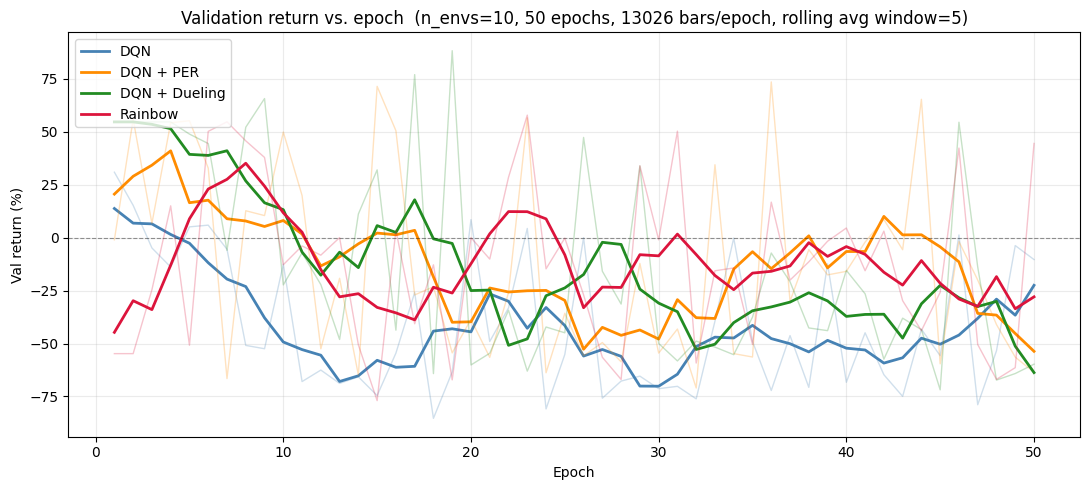

saved → runs/comparison.png

Final val returns (last epoch):
  DQN               -10.36%
  DQN + PER         -63.58%
  DQN + Dueling     -59.73%
  Rainbow           +44.44%

Best val return per model:
  DQN               +30.88%  (epoch 1)
  DQN + PER         +73.50%  (epoch 36)
  DQN + Dueling     +88.23%  (epoch 19)
  Rainbow           +57.82%  (epoch 23)


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
import matplotlib.pyplot as plt

from stable_baselines3 import DQN as VanillaDQN
from old_rainbow.rainbow_dqn import RainbowDQN

# ── setup ─────────────────────────────────────────────────────────────────────
N_EPOCHS = 50
N_ENVS   = 10

def make_train_env():
    return AssetVecEnv(
        make_config(df[mask_train].reset_index(drop=True)),
        n_envs=N_ENVS, **ENV_KWARGS,
    )

T_TRAIN = AssetVecEnv(
    make_config(df[mask_train].reset_index(drop=True)), n_envs=1, **ENV_KWARGS
).T
steps_per_epoch = T_TRAIN   # SB3 timestep budget per epoch

SHARED = dict(
    learning_starts      = min(500, T_TRAIN // 4),
    batch_size           = 64,
    learning_rate        = 1e-4,
    exploration_fraction = 0.5,   # epsilon decays over first 25 epochs
    verbose              = 0,
)

models = {
    "DQN":           VanillaDQN("MlpPolicy", make_train_env(), **SHARED),
    "DQN + PER":     RainbowDQN("MlpPolicy", make_train_env(), dueling=False, per=True,  **SHARED),
    "DQN + Dueling": RainbowDQN("MlpPolicy", make_train_env(), dueling=True,  per=False, **SHARED),
    "Rainbow":       RainbowDQN("MlpPolicy", make_train_env(), dueling=True,  per=True,  **SHARED),
}

# ── training loop ─────────────────────────────────────────────────────────────
history = {name: [] for name in models}

for epoch in range(N_EPOCHS):
    for name, model in models.items():
        model.learn(
            total_timesteps     = steps_per_epoch,
            reset_num_timesteps = (epoch == 0),
        )
        ep = eval_episode(model, val_env)
        history[name].append(ep["r"])

    if (epoch + 1) % 5 == 0:
        print(f"epoch {epoch+1:3d}/{N_EPOCHS}  " +
              "  ".join(f"{n}: {history[n][-1]:+.1%}" for n in models))

# ── plot ──────────────────────────────────────────────────────────────────────
import os
os.makedirs("runs", exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 5))
COLORS = {
    "DQN":           "steelblue",
    "DQN + PER":     "darkorange",
    "DQN + Dueling": "forestgreen",
    "Rainbow":       "crimson",
}
W = 5   # rolling-average window

for name, vals in history.items():
    raw    = np.array(vals) * 100
    smooth = pd.Series(raw).rolling(W, min_periods=1, center=True).mean().values
    col    = COLORS[name]
    ax.plot(range(1, N_EPOCHS + 1), raw,    color=col, alpha=0.25, linewidth=1.0)
    ax.plot(range(1, N_EPOCHS + 1), smooth, color=col, alpha=1.00, linewidth=2.0, label=name)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.4)
ax.set_xlabel("Epoch")
ax.set_ylabel("Val return (%)")
ax.set_title(
    f"Validation return vs. epoch  "
    f"(n_envs={N_ENVS}, {N_EPOCHS} epochs, {T_TRAIN} bars/epoch, "
    f"rolling avg window={W})"
)
ax.legend(loc="upper left")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig("runs/comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved → runs/comparison.png")

# ── final summary ─────────────────────────────────────────────────────────────
print("\nFinal val returns (last epoch):")
for name, vals in history.items():
    print(f"  {name:<16s}  {vals[-1]:+.2%}")
print("\nBest val return per model:")
for name, vals in history.items():
    best = max(vals)
    print(f"  {name:<16s}  {best:+.2%}  (epoch {np.argmax(vals)+1})")


## Backtest

In [19]:
from backtest import (
    price_series_from_env, infer_periods,
    activity_to_equity, activity_to_returns,
    metrics, tearsheet,
)

# ── run one test episode ──────────────────────────────────────────────────────
test_ep  = eval_episode(model, test_env)
activity = test_ep["activity"]
print(f"test  r={test_ep['r']:+.4%}  signals={test_ep['l']}  activity rows={len(activity)}")
print(activity.head(10).to_string())

# ── reconstruct equity & returns ──────────────────────────────────────────────
price  = price_series_from_env(test_env)
equity = activity_to_equity(activity, price)
ret    = activity_to_returns(activity, price)
print(f"price  rows={len(price)}")
print(f"equity rows={len(equity)}  start={equity.iloc[0]:,.2f}  end={equity.iloc[-1]:,.2f}")
print(f"ret    rows={len(ret)}")

# ── scalar metrics ────────────────────────────────────────────────────────────
periods = infer_periods(price)
print(f"periods (bars/year) = {periods}")

m = metrics(ret, equity, periods)
print("" + pd.Series(m).to_frame("value").to_string())

# ── sanity check: equity vs env ─────────────────────────────────────────────
print(f"equity  start={equity.iloc[0]:,.2f}  end={equity.iloc[-1]:,.2f}")
print(f"equity total return = {equity.iloc[-1]/equity.iloc[0]-1:+.4%}")
print(f"env    total return = {test_ep['r']:+.4%}")

# ── HTML tearsheet ────────────────────────────────────────────────────────────
import os
os.makedirs("runs", exist_ok=True)
tearsheet(ret, output="runs/test_tearsheet.html", title="DQN – test split")
print("tearsheet → runs/test_tearsheet.html")


test  r=-4.6927%  signals=79  activity rows=80
                     signal_type  leverage  position_size          cash          debt
Date                                                                                 
2019-12-30 23:00:00            0       0.0       0.000000  10000.000000      0.000000
2020-02-11 16:00:00            1       1.0      43.145893      0.000000      0.000000
2020-02-11 21:00:00            4       0.0       0.000000  10192.076172      0.000000
2020-02-12 00:00:00            1       1.0      41.210522      0.000000      0.000000
2020-02-12 02:00:00            4       0.0       0.000000  10041.606445      0.000000
2020-02-12 03:00:00            1       1.0      41.075935      0.000000      0.000000
2020-02-12 14:00:00            4       0.0       0.000000  10500.000000      0.000000
2020-02-12 16:00:00            1       1.0      40.036259      0.000000      0.000000
2020-02-12 18:00:00            4       0.0       0.000000  10638.594727      0.000000
2020-02